[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/reduce.ipynb)

# Reducing correlations

`K` features give `K(K+1)/2` correlations at every timepoint, and each higher order squares that count again. This notebook shows the ways to reduce them: models by name, graph measures, and two summaries of squared correlations (`WeightedStrength` and `Communities`).

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# If the install from PyPI fails, it falls back to GitHub master.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. Data with modules

`tc.simulate_nested` places nodes in modules, and nodes in the same module are coupled, and the coupling changes over time. `truth['module']` gives each node's module. We compute each subject's own dynamic correlations without reduction.

In [3]:
data, truth = tc.simulate_nested(S=2, T=1000, set_random_seed=0)
K = data[0].shape[1]
print(f'{len(data)} subjects, {K} nodes in {truth["module"].max() + 1} modules')

kernel = {'cfun': tc.autofc, 'weights_params': {'var': 100}}
corrs = tc.timecorr(data, **kernel)
print('unreduced correlations per subject:', corrs[0].shape)
for order in (1, 2, 3):
    n = K
    for _ in range(order):
        n = n * (n + 1) // 2
    print(f'order {order} without reduction: {n:,} features')

2 subjects, 108 nodes in 18 modules


unreduced correlations per subject: (1000, 5886)
order 1 without reduction: 5,886 features
order 2 without reduction: 17,325,441 features
order 3 without reduction: 150,085,461,584,961 features


## 2. Models by name

`rfun` in `tc.timecorr` (or `tc.reduce` on correlations you already have) accepts a hypertools or scikit-learn model name such as `'PCA'` or `'FastICA'`, with `K` output columns unless `ndims` says otherwise. One model is fit to all subjects of a list, and a dict passes parameters to the model.

In [4]:
pca = tc.timecorr(data, rfun='PCA', **kernel)
print('rfun="PCA":', [x.shape for x in pca])

reduced = tc.reduce(corrs, rfun='PCA', ndims=10)
print('reduce(..., ndims=10):', [x.shape for x in reduced])

ica = tc.reduce(corrs, rfun={'model': 'FastICA', 'params': {'max_iter': 1000}}, ndims=5)
print('FastICA with parameters:', [x.shape for x in ica])

rfun="PCA": [(1000, 108), (1000, 108)]
reduce(..., ndims=10): [(1000, 10), (1000, 10)]


FastICA with parameters: [(1000, 5), (1000, 5)]


## 3. Graph measures

Each timepoint's correlation matrix can be read as a network, and `'strength'` (the row sum), `'eigenvector_centrality'` and `'pagerank_centrality'` give one value per node. Signed correlations are used as they are, so negative correlations lower strength. The API reference explains when PageRank is not defined for signed weights.

strength                 (1000, 108)


eigenvector_centrality   (1000, 108)


pagerank_centrality      (1000, 108)


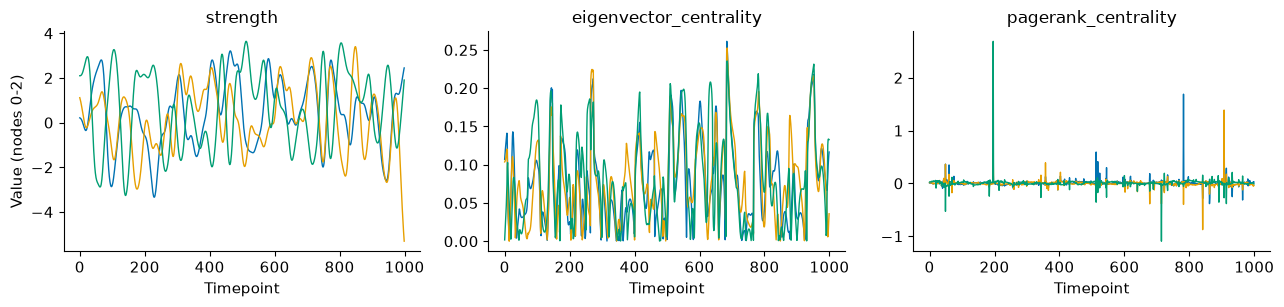

In [5]:
measures = {}
for name in ['strength', 'eigenvector_centrality', 'pagerank_centrality']:
    measures[name] = tc.reduce(corrs[0], rfun=name)
    print(f'{name:24s} {measures[name].shape}')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (name, m) in zip(axes, measures.items()):
    ax.plot(m[:, :3], lw=1)
    ax.set(title=name, xlabel='Timepoint')
axes[0].set_ylabel('Value (nodes 0-2)')
fig.tight_layout()
plt.show()

`'pagerank_centrality_abs'` runs PageRank on the absolute correlations, which is defined for every correlation matrix and gives values that sum to 1 at each timepoint.

In [6]:
pr_abs = tc.reduce(corrs[0], rfun='pagerank_centrality_abs')
print('pagerank_centrality_abs', pr_abs.shape,
      '| sums to 1 at every timepoint:', np.allclose(pr_abs.sum(1), 1))

pagerank_centrality_abs (1000, 108) | sums to 1 at every timepoint: True


## 4. Summaries of squared correlations

Squared correlations measure how strongly two nodes are coupled, whatever the sign. The two summaries are objects with `fit` (learn), `transform` (apply) and `fits_` (what was learned), and either can be passed wherever `rfun` is accepted. `tc.Communities(n)` finds `n` communities of nodes from the mean squared correlations and gives each community's mean squared correlation over time.

In [7]:
from sklearn.metrics import adjusted_rand_score

n_modules = truth['module'].max() + 1
communities = tc.Communities(n=n_modules).fit(corrs)
summary = communities.transform(corrs)
labels = communities.fits_[-1]['labels']
print('Communities:', [x.shape for x in summary])
print('agreement with the simulated modules (adjusted Rand index):',
      round(adjusted_rand_score(truth['module'], labels), 2))

Communities: [(1000, 18), (1000, 18)]
agreement with the simulated modules (adjusted Rand index): 1.0


`tc.WeightedStrength()` gives each node a weighted sum of its squared correlations, with more weight on partners that are coupled on average. Those weights (each pair's mean squared correlation) are centered before use: the sorted weights are divided where they best separate a low group from a high group, the mean of the low group is subtracted, and negative results are set to 0, so weakly coupled pairs get no weight (`center="median"` subtracts the median instead, and `center=False` uses the weights as they are). `signed=True` adds signed columns, and `split=True` splits each node's partners into its own community and the others.

In [8]:
strength = tc.WeightedStrength(signed=True).fit(corrs).transform(corrs)
print('WeightedStrength(signed=True):', [x.shape for x in strength])
same = tc.timecorr(data, rfun=tc.WeightedStrength(signed=True), **kernel)
print('same as rfun=WeightedStrength(signed=True):', all(np.allclose(a, b) for a, b in zip(same, strength)))

WeightedStrength(signed=True): [(1000, 216), (1000, 216)]


same as rfun=WeightedStrength(signed=True): True


`transform(..., fit_index=...)` chooses which subject's fit each new unit uses: a list gives one fitted subject per unit (here a reordered list keeps each subject's own fit), and an int applies one subject's fit to every unit (for example to a held-out subject).

In [9]:
ws = tc.WeightedStrength().fit(corrs)
reordered = ws.transform(corrs[::-1], fit_index=[1, 0])
print('reordered list, own fits:',
      all(np.allclose(a, b) for a, b in zip(reordered, ws.transform(corrs)[::-1])))
shared = ws.transform(corrs, fit_index=0)
print('both subjects with the fit of subject 0:', [x.shape for x in shared])

reordered list, own fits: True


both subjects with the fit of subject 0: [(1000, 108), (1000, 108)]


The left panel shows the mean squared correlation of every pair of nodes, with nodes sorted by the communities found. The blocks on the diagonal are the communities. The right panel shows each community's summary over time for one subject.

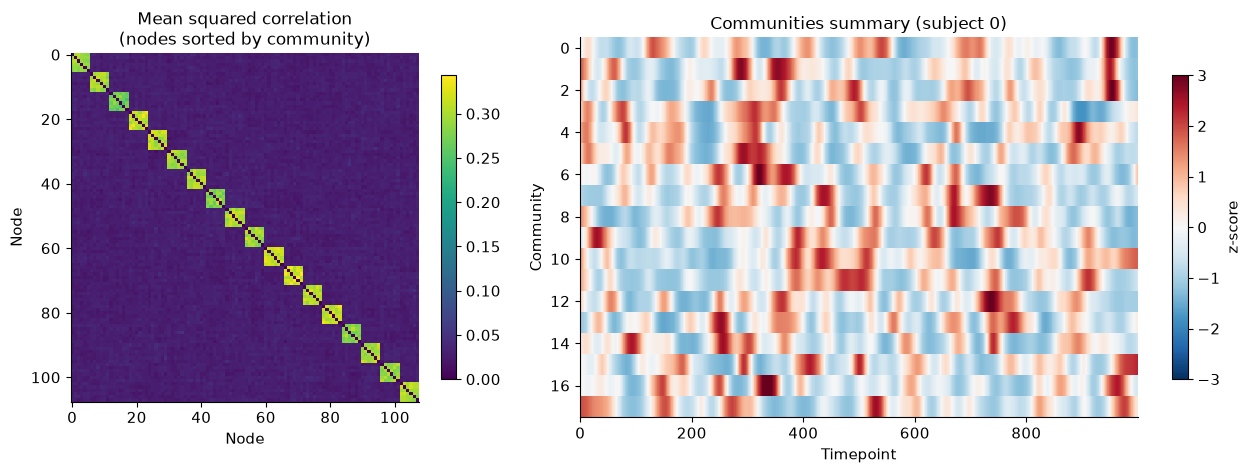

In [10]:
weights = np.mean(communities.fits_[-1]['weights'], axis=0)
order = np.argsort(labels, kind='stable')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.6]})
im = axes[0].imshow(weights[np.ix_(order, order)], cmap='viridis', interpolation='nearest')
axes[0].set(title='Mean squared correlation\n(nodes sorted by community)', xlabel='Node', ylabel='Node')
fig.colorbar(im, ax=axes[0], shrink=0.8)
z = (summary[0] - summary[0].mean(0)) / summary[0].std(0)
im = axes[1].imshow(z.T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
axes[1].set(title='Communities summary (subject 0)', xlabel='Timepoint', ylabel='Community')
fig.colorbar(im, ax=axes[1], label='z-score', shrink=0.8)
fig.tight_layout()
plt.show()

## 5. Choosing the number of communities

Without `n`, `Communities()` chooses the number of communities with a shift null (described in the API reference). This works inside `tc.features` and `tc.two_path_step`, which use it on the feeding path (see the [higher-order tutorial](higher_order.ipynb)).

In [11]:
automatic = tc.Communities()
tc.two_path_step(data, cfun=tc.autofc, delta_rfun=automatic)
found = automatic.fits_[0]
print(f'communities found: {found["n"]}; simulated modules: {n_modules}')
print('agreement with the simulated modules (adjusted Rand index):',
      round(adjusted_rand_score(truth['module'], found['labels']), 2))

communities found: 18; simulated modules: 18
agreement with the simulated modules (adjusted Rand index): 1.0


Next: [simulating data](simulate.ipynb).